# BatchNorm selection comparison

This notebook compares the CIFAR-10 RhoLoss BatchNorm runs in four ways:

1. Selection overlap over time.
2. Rho-score/rank differences.
3. Selection persistence and concentration.
4. Class composition and image-level disagreement sets.

The analyses are paired by seed across `eval`, `train`, and `batch_stats_no_update`. The saved artifacts are read from `experiments/BatchNorm/9-29-26`.

In [1]:
from pathlib import Path
from itertools import combinations
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import seaborn as sns
except ImportError:
    sns = None

try:
    from scipy.stats import rankdata
except ImportError:
    def rankdata(values):
        return pd.Series(values).rank(method='average').to_numpy()

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
METHODS = ['eval', 'train', 'batch_stats_no_update']
METHOD_LABELS = {
    'eval': 'eval',
    'train': 'train',
    'batch_stats_no_update': 'batch stats, no update',
}
PAIR_ORDER = list(combinations(METHODS, 2))
PAIR_LABELS = {f'{a} vs {b}': (a, b) for a, b in PAIR_ORDER}

def find_repo_root():
    for candidate in (Path.cwd(), Path.cwd().parent):
        if (candidate / 'experiments').exists() and (candidate / 'configs').exists():
            return candidate
    raise FileNotFoundError('Could not find the repository root from the notebook working directory.')

REPO_ROOT = find_repo_root()
RUN_ROOT = REPO_ROOT / 'experiments' / 'BatchNorm' / '9-29-26'
print('Repository:', REPO_ROOT)
print('Run root:', RUN_ROOT)

Repository: /home/todd30ap/online-batch-selection
Run root: /home/todd30ap/online-batch-selection/experiments/BatchNorm/9-29-26


In [2]:
# Discover runs and check that the expected artifacts exist.
RUN_RE = re.compile(r'^\d+_\d+_CIFAR10_RhoLoss_selection-(?P<method>.+)_Seed-(?P<seed>\d+)$')
records = []
for run_dir in sorted(RUN_ROOT.iterdir()):
    if not run_dir.is_dir():
        continue
    match = RUN_RE.match(run_dir.name)
    if match is None:
        continue
    method = match.group('method')
    seed = int(match.group('seed'))
    records.append({
        'run_dir': run_dir,
        'method': method,
        'seed': seed,
        'selected_path': run_dir / 'selected_points.npy',
        'trace_path': run_dir / 'selection_trace.npz',
    })

runs = pd.DataFrame(records).sort_values(['seed', 'method']).reset_index(drop=True)
runs['selected_exists'] = runs['selected_path'].map(Path.exists)
runs['trace_exists'] = runs['trace_path'].map(Path.exists)
display(runs[['seed', 'method', 'selected_exists', 'trace_exists', 'run_dir']])

if set(runs['method']) != set(METHODS):
    warnings.warn(f"Expected methods {METHODS}, found {sorted(runs['method'].unique())}.")
if not runs['selected_exists'].all():
    raise FileNotFoundError('At least one run is missing selected_points.npy.')
if not runs['trace_exists'].all():
    raise FileNotFoundError('At least one run is missing selection_trace.npz.')

RUNS = {(int(row.seed), row.method): row for row in runs.itertuples()}
SEEDS = sorted(runs['seed'].unique())
first_selected = np.load(runs.iloc[0]['selected_path'], mmap_mode='r')
NUM_EPOCHS, NUM_POINTS = first_selected.shape
print(f'{len(runs)} runs, {NUM_EPOCHS} epochs, {NUM_POINTS} training points')

,seed,method,selected_exists,trace_exists,run_dir
0,1,batch_stats_no_update,True,True,/home/todd30ap/online-batch-selection/experime...
1,1,eval,True,True,/home/todd30ap/online-batch-selection/experime...
2,1,train,True,True,/home/todd30ap/online-batch-selection/experime...
3,2,batch_stats_no_update,True,True,/home/todd30ap/online-batch-selection/experime...
4,2,eval,True,True,/home/todd30ap/online-batch-selection/experime...
5,2,train,True,True,/home/todd30ap/online-batch-selection/experime...
6,3,batch_stats_no_update,True,True,/home/todd30ap/online-batch-selection/experime...
7,3,eval,True,True,/home/todd30ap/online-batch-selection/experime...
8,3,train,True,True,/home/todd30ap/online-batch-selection/experime...
9,4,batch_stats_no_update,True,True,/home/todd30ap/online-batch-selection/experime...


15 runs, 500 epochs, 50000 training points


## 1. Selection overlap

Each point is represented by its per-epoch selected/not-selected mask. Jaccard overlap measures how similar two methods' selected sets are, independent of the absolute number selected.

,mean,std
pair,,
train vs batch_stats_no_update,0.694213,0.280136
eval vs batch_stats_no_update,0.475165,0.187745
eval vs train,0.473129,0.187745


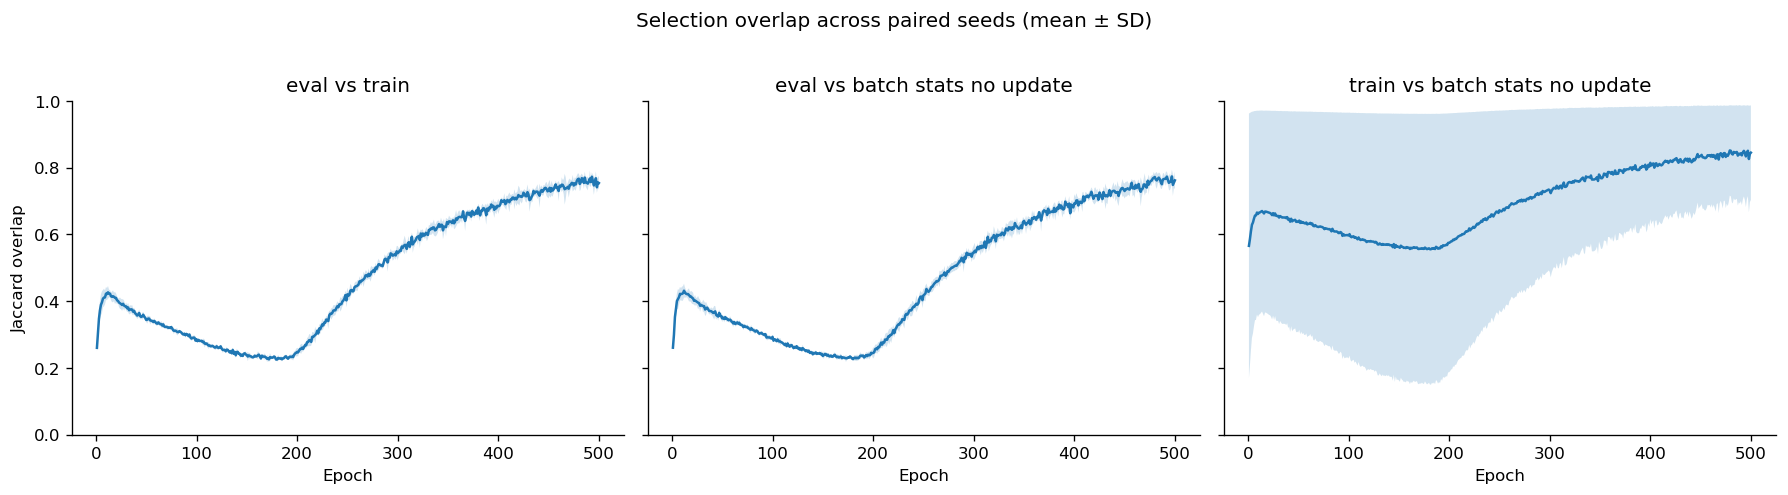

In [3]:
def selected_mask(seed, method):
    return np.load(RUNS[(seed, method)].selected_path, mmap_mode='r').astype(bool)

def jaccard_by_epoch(mask_a, mask_b):
    intersection = np.logical_and(mask_a, mask_b).sum(axis=1)
    union = np.logical_or(mask_a, mask_b).sum(axis=1)
    return intersection / np.maximum(union, 1)

overlap_rows = []
for seed in SEEDS:
    for method_a, method_b in PAIR_ORDER:
        values = jaccard_by_epoch(selected_mask(seed, method_a), selected_mask(seed, method_b))
        for epoch, value in enumerate(values, start=1):
            overlap_rows.append({
                'seed': seed, 'epoch': epoch,
                'pair': f'{method_a} vs {method_b}', 'jaccard': value,
            })
overlap_df = pd.DataFrame(overlap_rows)

fig, axes = plt.subplots(1, len(PAIR_ORDER), figsize=(15, 4), sharey=True)
for ax, (method_a, method_b) in zip(axes, PAIR_ORDER):
    pair = f'{method_a} vs {method_b}'
    grouped = overlap_df[overlap_df['pair'] == pair].groupby('epoch')['jaccard']
    mean = grouped.mean()
    std = grouped.std().fillna(0)
    ax.plot(mean.index, mean, label='mean')
    ax.fill_between(mean.index, mean - std, mean + std, alpha=0.2)
    ax.set_title(pair.replace('_', ' '))
    ax.set_xlabel('Epoch')
    ax.set_ylim(0, 1)
axes[0].set_ylabel('Jaccard overlap')
fig.suptitle('Selection overlap across paired seeds (mean ± SD)', y=1.02)
plt.tight_layout()
display(overlap_df.groupby('pair')['jaccard'].agg(['mean', 'std']).sort_values('mean', ascending=False))

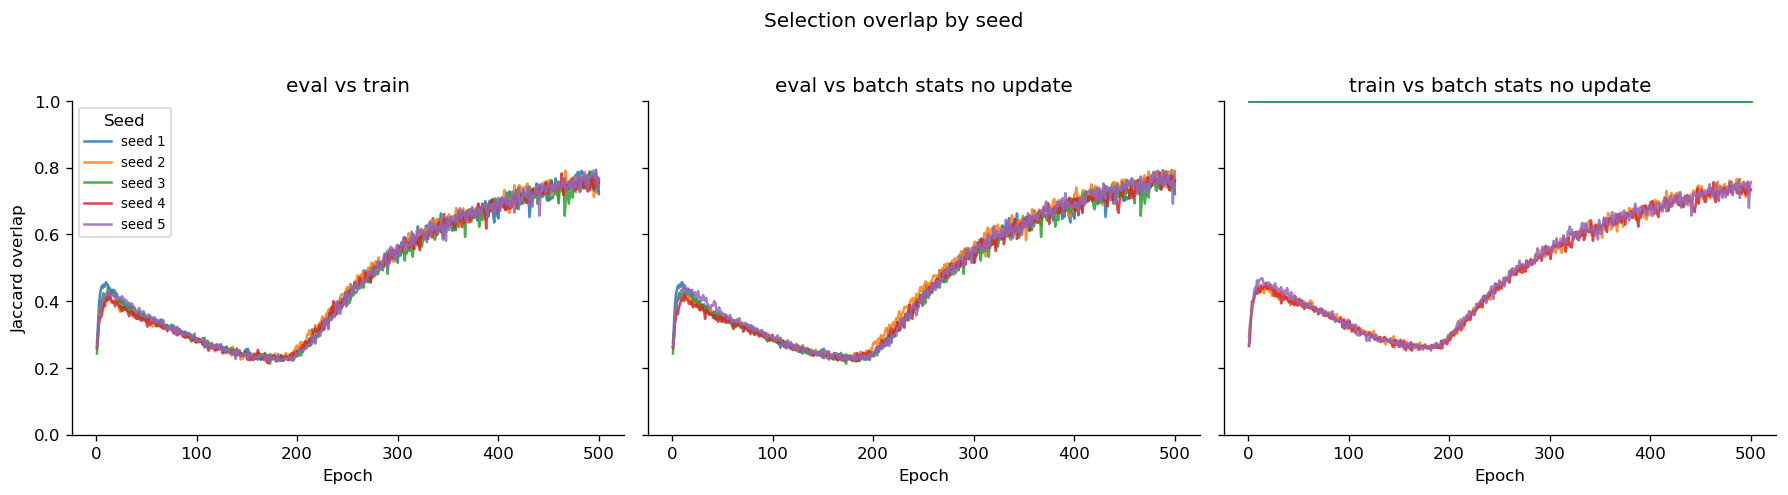

In [4]:
# Per-seed version of the Jaccard-overlap plot.
fig, axes = plt.subplots(1, len(PAIR_ORDER), figsize=(15, 4), sharey=True)
for ax, (method_a, method_b) in zip(axes, PAIR_ORDER):
    pair = f'{method_a} vs {method_b}'
    pair_df = overlap_df[overlap_df['pair'] == pair]
    for seed, seed_df in pair_df.groupby('seed'):
        ax.plot(seed_df['epoch'], seed_df['jaccard'], label=f'seed {seed}', alpha=0.85)
    ax.set_title(pair.replace('_', ' '))
    ax.set_xlabel('Epoch')
    ax.set_ylim(0, 1)
axes[0].set_ylabel('Jaccard overlap')
axes[0].legend(title='Seed', fontsize=8)
fig.suptitle('Selection overlap by seed', y=1.02)
plt.tight_layout()

## 2. Rho-score and ranking differences

`selection_trace.npz` stores, per epoch and dataset index, the selection mask, student loss, and Rho score. The loader below reads one trace column at a time so that the notebook does not retain all ~382 MB trace files simultaneously.

,spearman_rho_score,top_selection_overlap
pair,,
eval vs batch_stats_no_update,0.852219,0.622266
eval vs train,0.850988,0.620295
train vs batch_stats_no_update,0.919200,0.785045


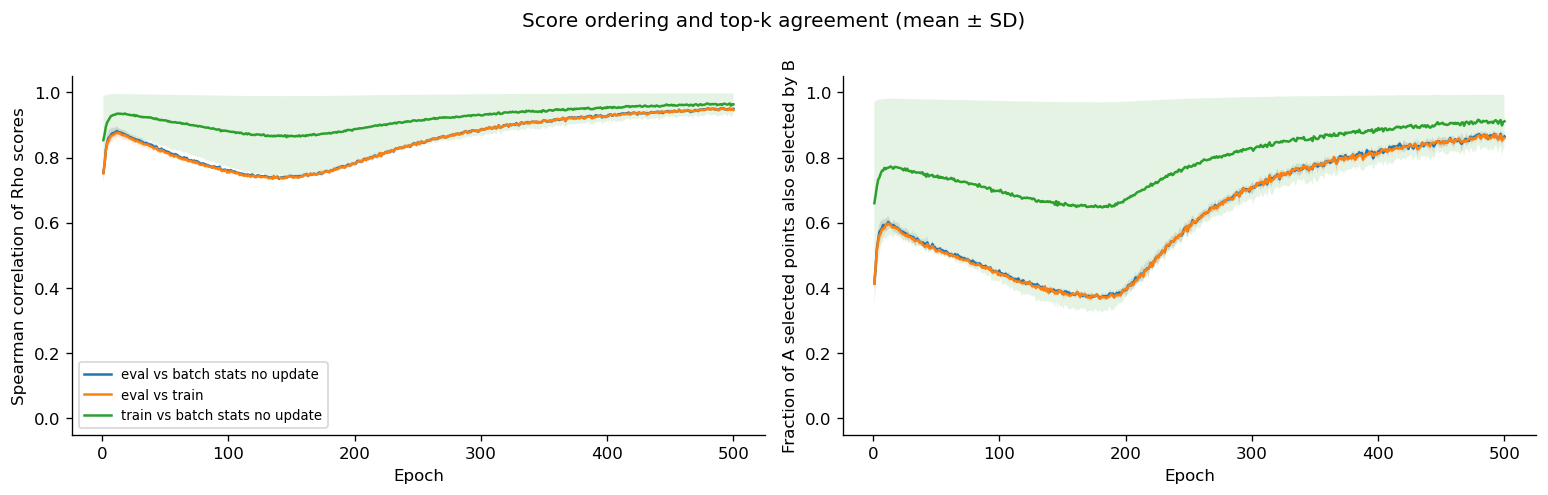

In [5]:
# Trace columns after the artifact's dataset-index column:
# 0 = total_steps, 1 = selected_mask, 2 = student_loss, 3 = rho_score.
def trace_column(seed, method, column):
    with np.load(RUNS[(seed, method)].trace_path, allow_pickle=False) as archive:
        return np.array(archive['trace'][:, :, column], dtype=np.float32, copy=True)

def safe_rank_correlation(a, b):
    finite = np.isfinite(a) & np.isfinite(b)
    if finite.sum() < 2:
        return np.nan
    ra = rankdata(a[finite])
    rb = rankdata(b[finite])
    if np.all(ra == ra[0]) or np.all(rb == rb[0]):
        return np.nan
    return float(np.corrcoef(ra, rb)[0, 1])

score_rows = []
for seed in SEEDS:
    for method_a, method_b in PAIR_ORDER:
        score_a = trace_column(seed, method_a, 3)
        score_b = trace_column(seed, method_b, 3)
        mask_a = selected_mask(seed, method_a)
        mask_b = selected_mask(seed, method_b)
        for epoch in range(NUM_EPOCHS):
            score_rows.append({
                'seed': seed, 'epoch': epoch + 1,
                'pair': f'{method_a} vs {method_b}',
                'spearman_rho_score': safe_rank_correlation(score_a[epoch], score_b[epoch]),
                'top_selection_overlap': np.logical_and(mask_a[epoch], mask_b[epoch]).sum() / max(mask_a[epoch].sum(), 1),
            })
        del score_a, score_b
score_df = pd.DataFrame(score_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for pair, group in score_df.groupby('pair'):
    summary = group.groupby('epoch')
    for ax, column, ylabel in [
        (axes[0], 'spearman_rho_score', 'Spearman correlation of Rho scores'),
        (axes[1], 'top_selection_overlap', 'Fraction of A selected points also selected by B'),
    ]:
        stats = summary[column].agg(['mean', 'std']).fillna(0)
        ax.plot(stats.index, stats['mean'], label=pair.replace('_', ' '))
        ax.fill_between(stats.index, stats['mean'] - stats['std'], stats['mean'] + stats['std'], alpha=0.12)
        ax.set_xlabel('Epoch')
        ax.set_ylabel(ylabel)
axes[0].legend(fontsize=8)
axes[0].set_ylim(-0.05, 1.05)
axes[1].set_ylim(-0.05, 1.05)
fig.suptitle('Score ordering and top-k agreement (mean ± SD)', y=1.02)
plt.tight_layout()
display(score_df.groupby('pair')[['spearman_rho_score', 'top_selection_overlap']].mean())

## 3. Selection persistence and concentration

These summaries show whether a method repeatedly selects the same points or spreads selection across the dataset.

,seed,unique_points_fraction,mean_selections_per_point,median_selections_per_point,effective_sample_fraction,median_first_selection_epoch
method,,,,,,
batch_stats_no_update,3.0,0.832612,50.0,15.2,0.270617,25.8
eval,3.0,0.845364,50.0,15.8,0.272218,23.4
train,3.0,0.833528,50.0,15.2,0.270615,24.8


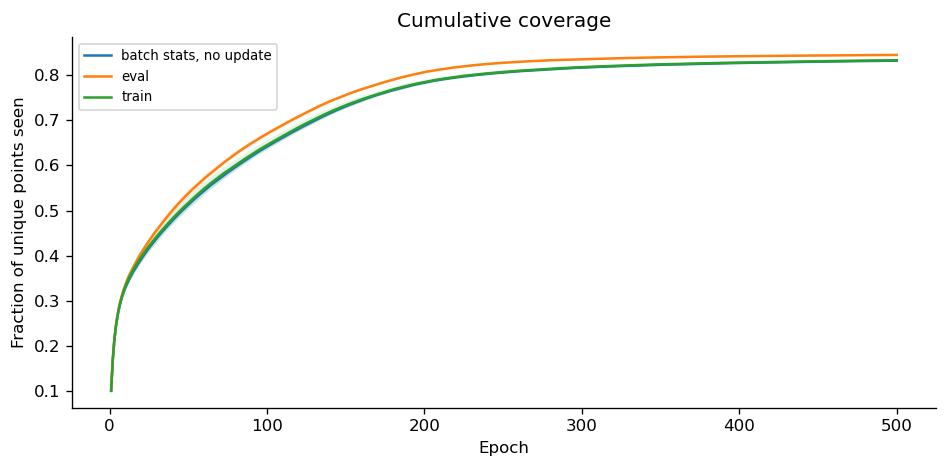

In [6]:
persistence_rows = []
coverage_rows = []
count_distributions = {}
for seed in SEEDS:
    for method in METHODS:
        mask = selected_mask(seed, method)
        counts = mask.sum(axis=0).astype(np.int32)
        cumulative_coverage = np.logical_or.accumulate(mask, axis=0).sum(axis=1) / NUM_POINTS
        probabilities = counts / max(counts.sum(), 1)
        effective_fraction = 1.0 / max((probabilities ** 2).sum(), 1e-12) / NUM_POINTS
        first_epoch = np.where(counts > 0, np.argmax(mask, axis=0) + 1, np.nan)
        persistence_rows.append({
            'seed': seed, 'method': method,
            'unique_points_fraction': np.mean(counts > 0),
            'mean_selections_per_point': counts.mean(),
            'median_selections_per_point': np.median(counts),
            'effective_sample_fraction': effective_fraction,
            'median_first_selection_epoch': np.nanmedian(first_epoch),
        })
        for epoch, value in enumerate(cumulative_coverage, start=1):
            coverage_rows.append({'seed': seed, 'method': method, 'epoch': epoch, 'coverage': value})
        count_distributions[(seed, method)] = counts

persistence_df = pd.DataFrame(persistence_rows)
coverage_df = pd.DataFrame(coverage_rows)

fig, ax = plt.subplots(figsize=(8, 4))
for method, group in coverage_df.groupby('method'):
    stats = group.groupby('epoch')['coverage'].agg(['mean', 'std']).fillna(0)
    ax.plot(stats.index, stats['mean'], label=METHOD_LABELS[method])
    ax.fill_between(stats.index, stats['mean'] - stats['std'], stats['mean'] + stats['std'], alpha=0.12)
ax.set(xlabel='Epoch', ylabel='Fraction of unique points seen', title='Cumulative coverage')
ax.legend(fontsize=8)
plt.tight_layout()
display(persistence_df.groupby('method').mean(numeric_only=True))

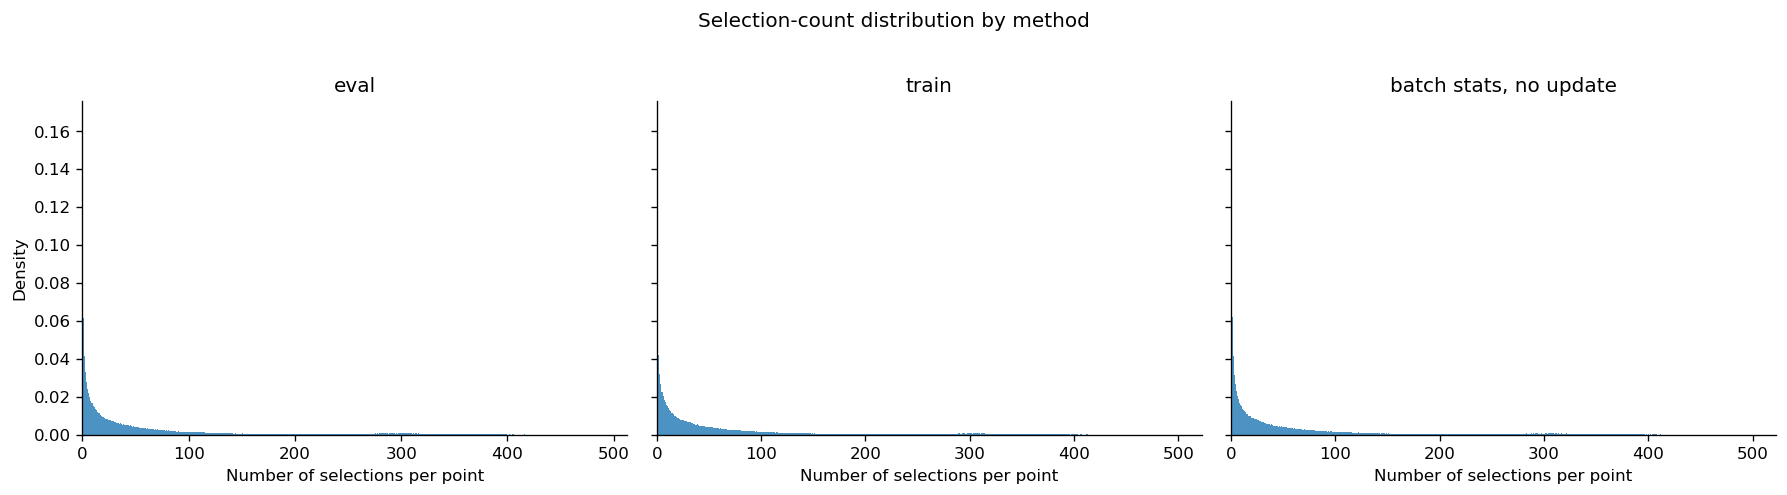

In [7]:
# Selection-count distributions, separated by method.
fig, axes = plt.subplots(1, len(METHODS), figsize=(15, 4), sharey=True)
for ax, method in zip(axes, METHODS):
    values = np.concatenate([count_distributions[(seed, method)] for seed in SEEDS])
    ax.hist(values, bins=np.arange(values.max() + 2) - 0.5, density=True, alpha=0.8)
    ax.set_title(METHOD_LABELS[method])
    ax.set_xlabel('Number of selections per point')
    ax.set_xlim(left=0)
axes[0].set_ylabel('Density')
fig.suptitle('Selection-count distribution by method', y=1.02)
plt.tight_layout()

## 4. What kinds of points differ?

The next cells compare class composition and show image grids for points selected by one method but not another. CIFAR-10 labels/images are loaded only if the local `_CIFAR` data is available.

Loaded CIFAR-10 labels and images: (50000, 32, 32, 3)


method,batch_stats_no_update,eval,train
class,,,
airplane,0.059525,0.053998,0.059794
automobile,0.039949,0.036612,0.039781
bird,0.107553,0.110361,0.108264
cat,0.102520,0.095304,0.102437
deer,0.137128,0.140164,0.137216
dog,0.089457,0.088580,0.089407
frog,0.096829,0.097320,0.096733
horse,0.263522,0.279897,0.263390
ship,0.045743,0.041742,0.045437


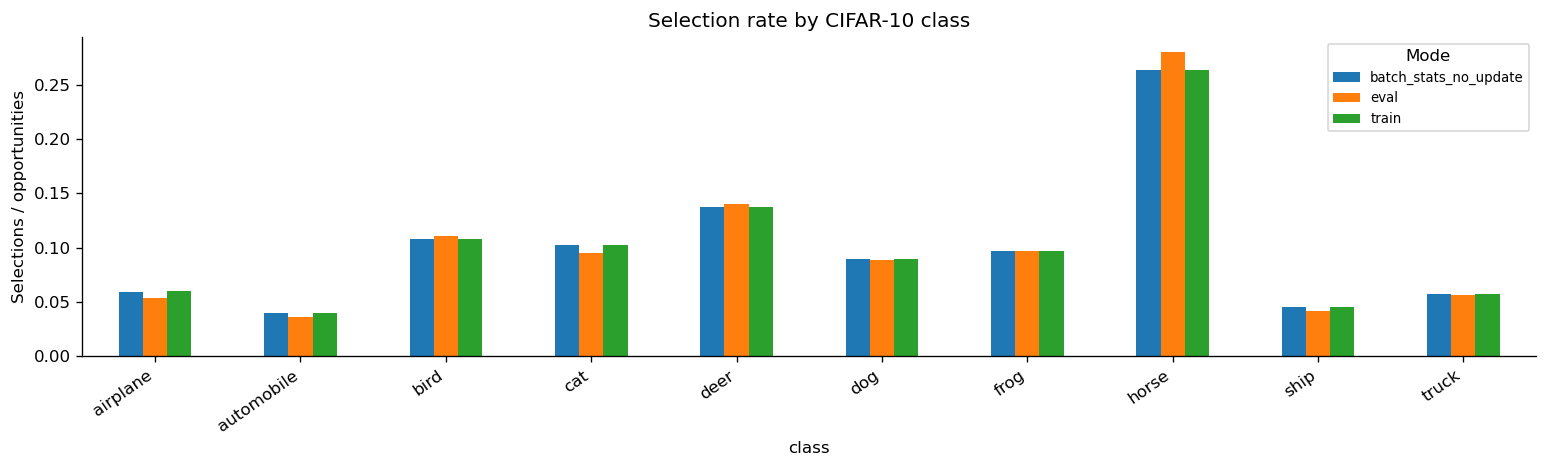

In [8]:
CIFAR_CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
cifar_labels = None
cifar_images = None
try:
    from torchvision.datasets import CIFAR10
    cifar = CIFAR10(root=str(REPO_ROOT / '_CIFAR'), train=True, download=False)
    cifar_labels = np.asarray(cifar.targets, dtype=np.int64)
    cifar_images = np.asarray(cifar.data)
    if len(cifar_labels) != NUM_POINTS:
        raise ValueError(f'CIFAR labels contain {len(cifar_labels)} points, expected {NUM_POINTS}.')
    print('Loaded CIFAR-10 labels and images:', cifar_images.shape)
except Exception as exc:
    warnings.warn(f'Could not load local CIFAR-10 data; class/image analyses will be skipped: {exc}')

if cifar_labels is not None:
    class_rows = []
    for seed in SEEDS:
        for method in METHODS:
            mask = selected_mask(seed, method)
            total_by_class = np.bincount(cifar_labels, minlength=10)
            selected_by_class = np.array([
                mask[:, cifar_labels == class_id].sum() for class_id in range(10)
            ])
            # Normalize by opportunities: class size times number of epochs.
            rate_by_class = selected_by_class / np.maximum(total_by_class * mask.shape[0], 1)
            for class_id, rate in enumerate(rate_by_class):
                class_rows.append({
                    'seed': seed, 'method': method, 'class_id': class_id,
                    'class': CIFAR_CLASSES[class_id], 'selection_rate': rate,
                })
    class_df = pd.DataFrame(class_rows)
    class_summary = class_df.groupby(['method', 'class'], as_index=False)['selection_rate'].mean()
    class_pivot = class_summary.pivot(index='class', columns='method', values='selection_rate').reindex(CIFAR_CLASSES)
    class_pivot.plot.bar(figsize=(13, 4))
    plt.ylabel('Selections / opportunities')
    plt.title('Selection rate by CIFAR-10 class')
    plt.xticks(rotation=35, ha='right')
    plt.legend(title='Mode', fontsize=8)
    plt.tight_layout()
    display(class_pivot)

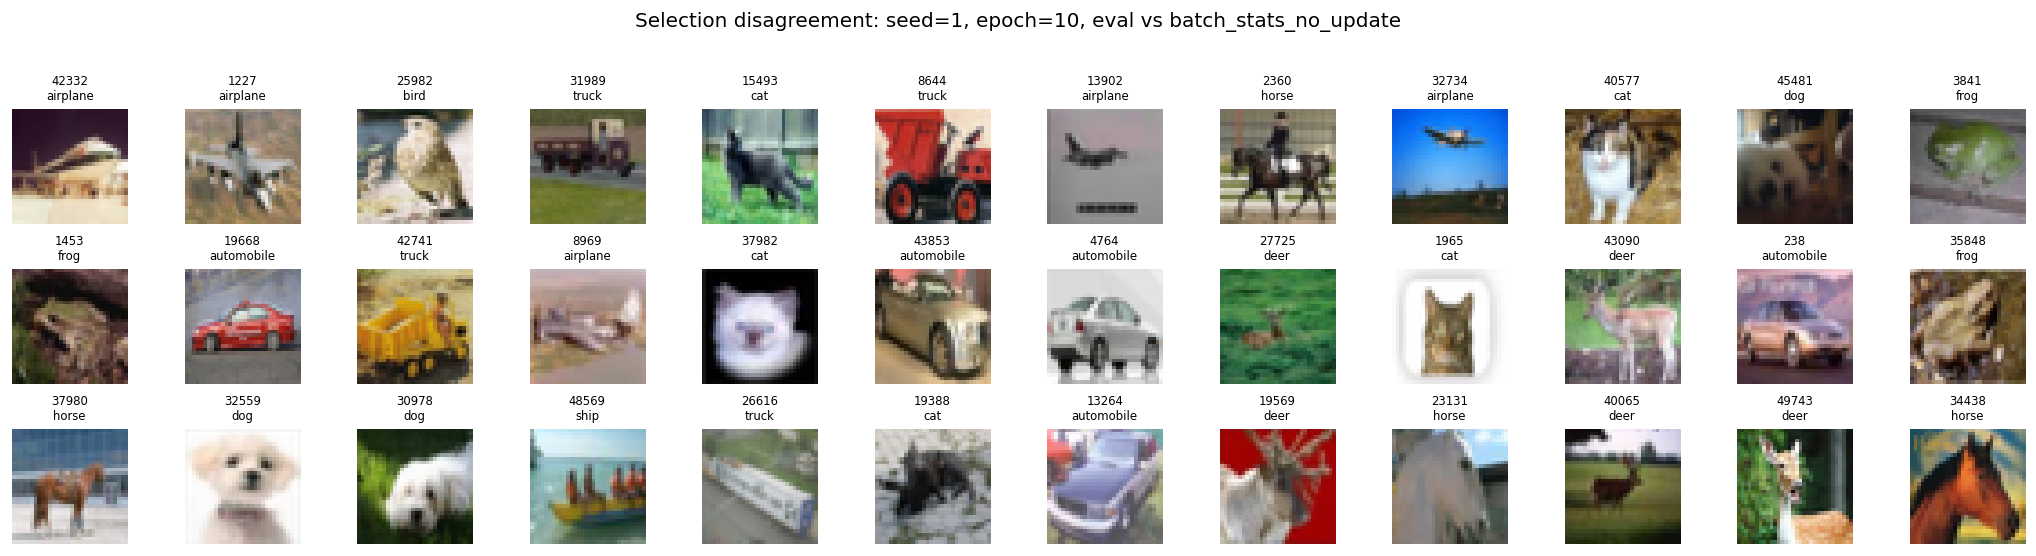

In [9]:
def disagreement_indices(seed, method_a, method_b, epoch, category='a_only'):
    a = selected_mask(seed, method_a)[epoch - 1]
    b = selected_mask(seed, method_b)[epoch - 1]
    if category == 'a_only':
        return np.flatnonzero(a & ~b)
    if category == 'b_only':
        return np.flatnonzero(b & ~a)
    if category == 'both':
        return np.flatnonzero(a & b)
    raise ValueError(category)

def plot_disagreement_grid(seed=1, method_a='eval', method_b='train', epoch=10, n=12, random_state=0):
    if cifar_images is None:
        print('CIFAR images are unavailable; skip this cell after making the dataset available.')
        return
    rng = np.random.default_rng(random_state)
    categories = [('a_only', f'{METHOD_LABELS[method_a]} only'), ('b_only', f'{METHOD_LABELS[method_b]} only'), ('both', 'both methods')]
    fig, axes = plt.subplots(len(categories), n, figsize=(1.45 * n, 4.5))
    axes = np.atleast_2d(axes)
    for row, (category, title) in enumerate(categories):
        indices = disagreement_indices(seed, method_a, method_b, epoch, category)
        if len(indices) > n:
            indices = rng.choice(indices, size=n, replace=False)
        for col in range(n):
            ax = axes[row, col]
            ax.axis('off')
            if col < len(indices):
                idx = int(indices[col])
                ax.imshow(cifar_images[idx])
                ax.set_title(f'{idx}\n{CIFAR_CLASSES[cifar_labels[idx]]}', fontsize=7)
        axes[row, 0].set_ylabel(title, fontsize=9)
    fig.suptitle(f'Selection disagreement: seed={seed}, epoch={epoch}, {method_a} vs {method_b}', y=1.02)
    plt.tight_layout()

# Change these controls to inspect other seeds, epochs, and method pairs.
plot_disagreement_grid(seed=1, method_a='eval', method_b='batch_stats_no_update', epoch=10)

### Interpretation notes

- Compare methods by the same seed first, then summarize variation across the five seeds.
- Same-epoch comparisons measure the combined effect of selection and the resulting training trajectory.
- For a more causal BatchNorm comparison, focus on early epochs or compare runs at matched train/validation progress.
- The `eval`/`batch_stats_no_update` contrast is the running-statistics versus batch-statistics comparison; `train` adds the effect of updating BatchNorm buffers during the selection pass.